# 08 Least squares: can plain linear regression match ridge?

In notebook 07 the best ridge model uses a **tiny** penalty (λ = 1e-3, and λ = 1e-4 scores the same): with
N ≈ 330k rows and about 1200 columns there is little overfitting to prevent. So why not drop the penalty and use
**`least_squares`** from `implementations.py`?

On the notebook 07 features it fails outright: `np.linalg.solve` raises *Singular matrix*. This notebook

1. explains why (exactly redundant columns) and fixes it by removing them **inside each fit**;
2. compares least squares with ridge on the same features, folds and undersampling;
3. replaces undersampling by **class-weighted least squares**, which keeps every row instead of discarding
   most of the negatives;
4. retrains the best least-squares model on all rows and writes `submission_least_squares_best.csv`.

Same evaluation as notebooks 05 and 07: stratified 5-fold CV, F1-tuned threshold on the out-of-fold scores.
Run time: about 10 minutes.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "implementations.py").exists():
    PROJECT_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import feature_engineering as fe
import implementations as impl
from cross_validation import build_k_indices, cross_validation, random_undersample
from helpers import create_csv_submission

warnings.filterwarnings("ignore", message=".*encountered in matmul")

K_FOLD = 5
SEED = 1
GROUPS = ("redundant", "risk_management", "optional_modules")   # as in notebook 07
INTERACT = ("_AGE80", "SEX=2")

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 2, "font.size": 10,
})

In [2]:
start = time.time()
raw = fe.load_raw(PROJECT_ROOT / "dataset")
decoded = fe.decode_missing(raw)
y = raw["y_train"]
k_indices = build_k_indices(y, K_FOLD, seed=SEED)

x_tr, x_te, names = fe.build_features(raw, keep_groups=GROUPS, decoded=decoded,
                                      square_numeric=True, interact_with=INTERACT)
tx = np.c_[np.ones(len(x_tr)), x_tr]
tx_test = np.c_[np.ones(len(x_te)), x_te]
names = np.r_[["bias"], names]
del x_tr, x_te
print(f"notebook 07 features: {tx.shape[1]} columns, {len(y)} rows  ({time.time() - start:.0f}s)")

notebook 07 features: 1236 columns, 328135 rows  (9s)


## 1. Why least squares fails, and the fix

Least squares solves `(XᵀX) w = Xᵀy`. If some columns are exact linear combinations of others, `XᵀX` is singular
and the solution is not unique. Here this happens because of how the features are built: for example a
one-hot column plus the other levels of the same variable adds up to the bias column, and some missing
indicators are identical to each other. Ridge adds `2Nλ I` to `XᵀX`, which hides the problem.

In [3]:
eigenvalues = np.linalg.eigvalsh(tx.T @ tx / len(y))
print(f"eigenvalues of XᵀX / N: largest {eigenvalues[-1]:.1f}, "
      f"{np.sum(eigenvalues < 1e-10)} are zero (< 1e-10) -> singular")
try:
    impl.least_squares(y, tx)
except np.linalg.LinAlgError as error:
    print(f"least_squares on all {tx.shape[1]} columns: LinAlgError: {error}")

keep_all = fe.independent_columns(tx)
dropped = np.setdiff1d(np.arange(tx.shape[1]), keep_all)
print(f"\nindependent columns: {len(keep_all)} of {tx.shape[1]} ({len(dropped)} redundant), e.g.")
print("  ", ", ".join(names[dropped][:10]))

eigenvalues of XᵀX / N: largest 69.4, 85 are zero (< 1e-10) -> singular
least_squares on all 1236 columns: LinAlgError: Singular matrix

independent columns: 1151 of 1236 (85 redundant), e.g.
   ASTHMAGE, ASRCHKUP, ASACTLIM, METVL11__missing, METVL21__missing, _CPRACE=1, _CPRACE=2, _CPRACE=3, _CPRACE=4, _CPRACE=5


**The fix.** `fe.independent_columns` keeps a maximal set of linearly independent columns (greedy Gram-Schmidt on
`XᵀX`). It must run **inside each fit**, on that fold's training rows: after undersampling, a rare one-hot level
can vanish from the training fold, which creates new redundancies (removing columns once on the full data still
gives *Singular matrix* in some folds). Removed columns simply get weight 0. The decision uses no labels.

In [4]:
def least_squares_reduced(y, tx, params):
    # impl.least_squares on the linearly independent columns of tx; the others get weight 0.
    keep = fe.independent_columns(tx)
    w = np.zeros(tx.shape[1])
    w[keep], _ = impl.least_squares(y, tx[:, keep])
    return w


def weighted_least_squares(y, tx, params):
    # Least squares where every positive row counts `params["c"]` times: minimizes
    # sum_i c_i (y_i - x_i w)^2, i.e. ordinary least squares on rows scaled by sqrt(c_i).
    s = np.sqrt(np.where(y == 1, params["c"], 1.0))
    return least_squares_reduced(y * s, tx * s[:, None], params)


def undersample(ratio):
    if ratio is None:
        return None
    return lambda x, y, seed: random_undersample(x, y, seed, ratio=ratio)


def run(model, params, ratio=None, label=""):
    start = time.time()
    r = cross_validation(y, tx, model, params, k_indices, resample_fn=undersample(ratio), seed=SEED)
    print(f"{label:<44} F1 = {r['f1_mean']:.4f} ± {r['f1_std']:.4f}   "
          f"P = {r['precision_mean']:.3f}  R = {r['recall_mean']:.3f}   ({time.time() - start:.0f}s)")
    return r

## 2. Least squares vs ridge, same features and same undersampling

`ratio` = negatives kept per positive in the training folds (`none` = all rows). Ridge uses notebook 07's λ = 1e-3.

In [5]:
ratios = [None, 1.0, 3.0, 5.0]
compare = {}
for ratio in ratios:
    tag = "none" if ratio is None else f"1:{ratio:g}"
    compare[("least squares", ratio)] = run(least_squares_reduced, {}, ratio, f"least squares, undersample {tag}")
    compare[("ridge", ratio)] = run("ridge_regression", {"lambda_": 1e-3}, ratio, f"ridge λ = 1e-3, undersample {tag}")

least squares, undersample none              F1 = 0.4290 ± 0.0047   P = 0.358  R = 0.535   (32s)
ridge λ = 1e-3, undersample none             F1 = 0.4294 ± 0.0038   P = 0.360  R = 0.532   (7s)
least squares, undersample 1:1               F1 = 0.4241 ± 0.0046   P = 0.351  R = 0.536   (17s)
ridge λ = 1e-3, undersample 1:1              F1 = 0.4278 ± 0.0061   P = 0.363  R = 0.521   (2s)
least squares, undersample 1:3               F1 = 0.4292 ± 0.0049   P = 0.357  R = 0.538   (20s)
ridge λ = 1e-3, undersample 1:3              F1 = 0.4316 ± 0.0043   P = 0.362  R = 0.534   (3s)
least squares, undersample 1:5               F1 = 0.4306 ± 0.0052   P = 0.354  R = 0.551   (22s)
ridge λ = 1e-3, undersample 1:5              F1 = 0.4317 ± 0.0045   P = 0.359  R = 0.542   (4s)


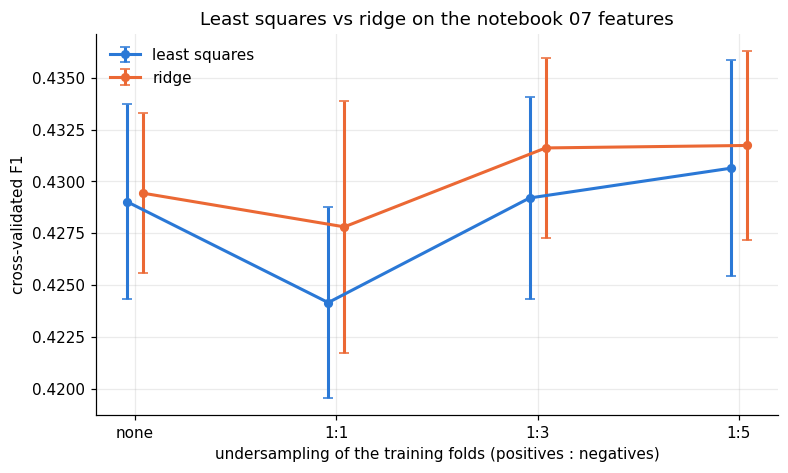

In [6]:
fig, ax = plt.subplots()
x_pos = np.arange(len(ratios))
for model, color, offset in [("least squares", BLUE, -0.04), ("ridge", ORANGE, 0.04)]:
    means = np.array([compare[(model, r)]["f1_mean"] for r in ratios])
    stds = np.array([compare[(model, r)]["f1_std"] for r in ratios])
    ax.errorbar(x_pos + offset, means, yerr=stds, color=color, marker="o", markersize=5, capsize=3, label=model)
ax.set_xticks(x_pos, ["none" if r is None else f"1:{r:g}" for r in ratios])
ax.set_xlabel("undersampling of the training folds (positives : negatives)")
ax.set_ylabel("cross-validated F1")
ax.set_title("Least squares vs ridge on the notebook 07 features")
ax.legend(frameon=False)
plt.show()

## 3. Class-weighted least squares instead of undersampling

Undersampling 1:5 throws away about half of the negatives in each training fold. Giving every positive row a
weight `c > 1` has a similar effect on the fit (the positives pull the regression line harder) but **keeps every
row**, and involves no randomness. With `c` = n_neg / n_pos ≈ 10.3 the two classes weigh the same in total.

weighted least squares, c = 1                F1 = 0.4290 ± 0.0047   P = 0.358  R = 0.535   (82s)
weighted least squares, c = 2                F1 = 0.4307 ± 0.0041   P = 0.356  R = 0.545   (80s)
weighted least squares, c = 3                F1 = 0.4314 ± 0.0038   P = 0.355  R = 0.550   (47s)
weighted least squares, c = 4                F1 = 0.4309 ± 0.0037   P = 0.350  R = 0.560   (219s)
weighted least squares, c = 6                F1 = 0.4303 ± 0.0052   P = 0.348  R = 0.564   (53s)
weighted least squares, c = 10.3             F1 = 0.4283 ± 0.0050   P = 0.349  R = 0.555   (39s)

best positive weight: c = 3


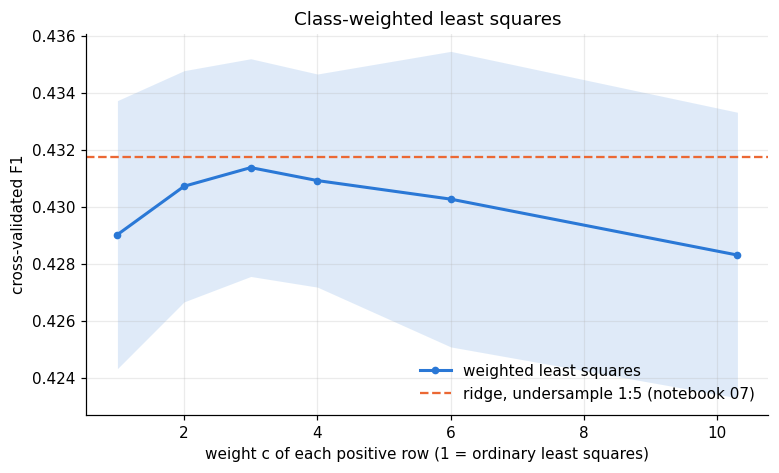

In [7]:
balanced_c = (y == 0).sum() / (y == 1).sum()
weights = [1.0, 2.0, 3.0, 4.0, 6.0, round(balanced_c, 1)]
weighted = {}
for c in weights:
    weighted[c] = run(weighted_least_squares, {"c": c}, None, f"weighted least squares, c = {c:g}")

BEST_C = max(weighted, key=lambda c: weighted[c]["f1_mean"])
print(f"\nbest positive weight: c = {BEST_C:g}")

fig, ax = plt.subplots()
means = np.array([weighted[c]["f1_mean"] for c in weights])
stds = np.array([weighted[c]["f1_std"] for c in weights])
ax.fill_between(weights, means - stds, means + stds, color=BLUE, alpha=0.15, linewidth=0)
ax.plot(weights, means, color=BLUE, marker="o", markersize=4, label="weighted least squares")
ax.axhline(compare[("ridge", 5.0)]["f1_mean"], color=ORANGE, linestyle="--", linewidth=1.5,
           label="ridge, undersample 1:5 (notebook 07)")
ax.set_xlabel("weight c of each positive row (1 = ordinary least squares)")
ax.set_ylabel("cross-validated F1")
ax.set_title("Class-weighted least squares")
ax.legend(frameon=False, loc="lower right")
plt.show()

## 4. Summary

model                                                 F1 precision recall threshold
ridge, undersample 1:5                   0.4317 ± 0.0045    0.3587 0.5421    0.3586
ridge, undersample 1:3                   0.4316 ± 0.0043    0.3621 0.5341    0.4710
weighted least squares, c = 3            0.4314 ± 0.0038    0.3548 0.5502    0.4312
weighted least squares, c = 4            0.4309 ± 0.0037    0.3500 0.5604    0.4858
weighted least squares, c = 2            0.4307 ± 0.0041    0.3561 0.5449    0.3501
least squares, undersample 1:5           0.4306 ± 0.0052    0.3536 0.5505    0.3542
weighted least squares, c = 6            0.4303 ± 0.0052    0.3480 0.5636    0.5695
ridge, undersample none                  0.4294 ± 0.0038    0.3600 0.5320    0.2296
least squares, undersample 1:3           0.4292 ± 0.0049    0.3572 0.5375    0.4681
least squares, undersample none          0.4290 ± 0.0047    0.3582 0.5348    0.2288
weighted least squares, c = 1            0.4290 ± 0.0047    0.3582 0.5348   

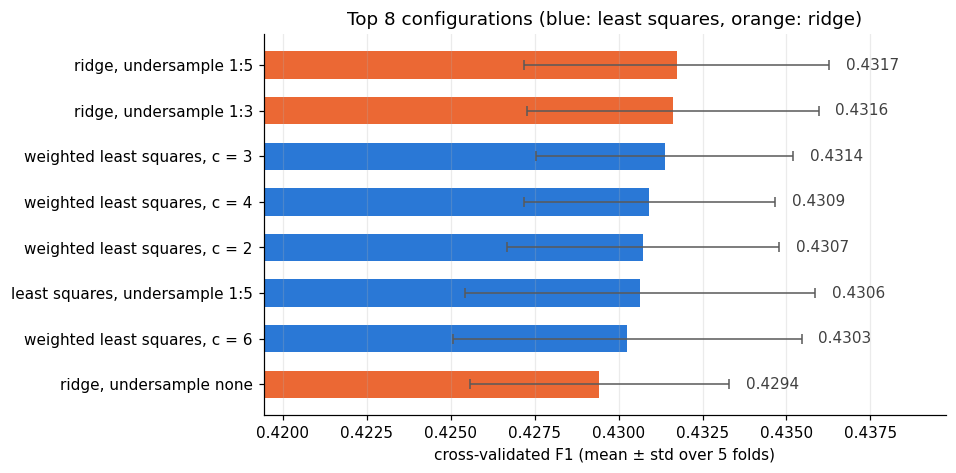

In [8]:
rows = [(f"{model}, undersample {'none' if r is None else f'1:{r:g}'}", res, model)
        for (model, r), res in compare.items()]
rows += [(f"weighted least squares, c = {c:g}", res, "weighted least squares") for c, res in weighted.items()]
rows.sort(key=lambda row: row[1]["f1_mean"], reverse=True)

print(f"{'model':<40} {'F1':>15} {'precision':>9} {'recall':>6} {'threshold':>9}")
for label, r, _ in rows:
    print(f"{label:<40} {r['f1_mean']:.4f} ± {r['f1_std']:.4f} {r['precision_mean']:>9.4f} "
          f"{r['recall_mean']:>6.4f} {r['threshold']:>9.4f}")

top = rows[:8][::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = [ORANGE if kind == "ridge" else BLUE for _, _, kind in top]
means = np.array([r["f1_mean"] for _, r, _ in top])
stds = np.array([r["f1_std"] for _, r, _ in top])
ax.barh([label for label, _, _ in top], means, xerr=stds, color=colors, height=0.6,
        error_kw={"ecolor": "0.35", "elinewidth": 1, "capsize": 3})
for i, v in enumerate(means):
    ax.text(v + stds[i] + 0.0005, i, f"{v:.4f}", va="center", color="0.25")
ax.set_xlim(means.min() - 0.01, means.max() + 0.008)
ax.set_xlabel("cross-validated F1 (mean ± std over 5 folds)")
ax.set_title("Top 8 configurations (blue: least squares, orange: ridge)")
ax.grid(axis="y", visible=False)
plt.show()

As in notebook 07, the threshold is tuned on the out-of-fold scores, so all numbers are slightly optimistic by the
same small amount. Differences below about one fold std (~0.004) are within noise.

## 5. Final least-squares model and submission

The best **least-squares** configuration of the summary (ridge rows excluded) is retrained on all training rows
and applied to the test set with the threshold chosen by cross-validation.

In [9]:
final_label, final_cv, _ = next(row for row in rows if row[2] != "ridge")
print(f"final model: {final_label}")

if final_label.startswith("weighted"):
    w_final = weighted_least_squares(y, tx, {"c": BEST_C})
    n_rows = len(y)
else:
    ratio = next(r for (m, r), res in compare.items() if m == "least squares" and res is final_cv)
    tx_fit, y_fit = (tx, y) if ratio is None else random_undersample(tx, y, seed=SEED, ratio=ratio)
    w_final = least_squares_reduced(y_fit, tx_fit, {})
    n_rows = len(y_fit)
print(f"trained on {n_rows} rows, {np.count_nonzero(w_final)} non-zero weights of {tx.shape[1]}")

threshold = final_cv["threshold"]
test_predictions = np.where(tx_test @ w_final >= threshold, 1, -1)
oof_rate = np.mean(final_cv["oof_scores"] >= threshold)
print(f"predicted positive rate: test {np.mean(test_predictions == 1):.4f}, out-of-fold {oof_rate:.4f}")

submission_path = PROJECT_ROOT / "submission_least_squares_best.csv"
create_csv_submission(raw["test_ids"], test_predictions, submission_path)
print(f"submission written to {submission_path}")

final model: weighted least squares, c = 3
trained on 328135 rows, 1151 non-zero weights of 1236
predicted positive rate: test 0.1378, out-of-fold 0.1369
submission written to /Users/ema/Desktop/EPFL/Machine Learning/ML_Project1/submission_least_squares_best.csv


## 6. Conclusions

CONCLUSIONS_PLACEHOLDER